In [1]:
# Data Handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Train-Test Split
from sklearn.model_selection import train_test_split

# Regression Models
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import plot_tree

# Evaluation Metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


In [2]:
df = pd.read_csv('Boston_Cleaned_Data.csv')

In [3]:
df

,ID,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
0,1,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
1,2,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
2,4,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
3,7,7.87,0,0.524,6.012,66.6,5.5605,5,311,15.2,12.43,22.9
4,11,7.87,0,0.524,6.377,94.3,6.3467,5,311,15.2,20.45,15.0
...,...,...,...,...,...,...,...,...,...,...,...,...
260,500,9.69,0,0.585,5.569,73.5,2.3999,6,391,19.2,15.10,17.5
261,502,11.93,0,0.573,6.593,69.1,2.4786,1,273,21.0,9.67,22.4
262,503,11.93,0,0.573,6.120,76.7,2.2875,1,273,21.0,9.08,20.6
263,504,11.93,0,0.573,6.976,91.0,2.1675,1,273,21.0,5.64,23.9


In [4]:
df.shape

(265, 12)

In [5]:
df.head()

,ID,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
0,1,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
1,2,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
2,4,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
3,7,7.87,0,0.524,6.012,66.6,5.5605,5,311,15.2,12.43,22.9
4,11,7.87,0,0.524,6.377,94.3,6.3467,5,311,15.2,20.45,15.0


In [6]:
df.isnull().sum()

ID         0
indus      0
chas       0
nox        0
rm         0
age        0
dis        0
rad        0
tax        0
ptratio    0
lstat      0
medv       0
dtype: int64

In [7]:
df.describe()

,ID,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
count,265.000000,265.000000,265.0,265.000000,265.000000,265.000000,265.000000,265.000000,265.000000,265.000000,265.000000,265.000000
mean,250.207547,11.703019,0.0,0.553661,6.172925,67.336226,3.825219,9.600000,415.407547,18.791321,12.815321,20.383774
std,159.250465,6.895159,0.0,0.112453,0.442629,28.253713,1.954277,8.838963,169.483171,1.884436,6.016210,5.588252
min,1.000000,0.740000,0.0,0.385000,4.963000,6.000000,1.285200,1.000000,188.000000,14.700000,2.940000,7.200000
25%,103.000000,5.640000,0.0,0.453000,5.880000,45.000000,2.256500,4.000000,287.000000,17.800000,7.880000,17.100000
50%,244.000000,9.900000,0.0,0.538000,6.151000,74.900000,3.215700,5.000000,337.000000,19.200000,12.010000,20.400000
75%,408.000000,18.100000,0.0,0.614000,6.437000,93.600000,5.287300,24.000000,666.000000,20.200000,16.740000,23.800000
max,506.000000,27.740000,0.0,0.871000,7.420000,100.000000,9.222900,24.000000,711.000000,21.200000,29.680000,33.400000


In [8]:
df.corr(numeric_only = True)

,ID,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
ID,1.000000,0.441230,NaN,0.462767,-0.026782,0.248120,-0.366415,0.706167,0.703749,0.330487,0.292612,-0.324491
indus,0.441230,1.000000,NaN,0.762427,-0.375973,0.637351,-0.746541,0.548037,0.676522,0.342545,0.647446,-0.583680
chas,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nox,0.462767,0.762427,NaN,1.000000,-0.298356,0.724045,-0.773957,0.625996,0.687868,0.247556,0.635372,-0.599879
rm,-0.026782,-0.375973,NaN,-0.298356,1.000000,-0.241014,0.306379,-0.127525,-0.192746,-0.156224,-0.517062,0.532557
age,0.248120,0.637351,NaN,0.724045,-0.241014,1.000000,-0.734701,0.426291,0.509339,0.309193,0.654143,-0.609412
dis,-0.366415,-0.746541,NaN,-0.773957,0.306379,-0.734701,1.000000,-0.476216,-0.562268,-0.325117,-0.570560,0.498542
rad,0.706167,0.548037,NaN,0.625996,-0.127525,0.426291,-0.476216,1.000000,0.899816,0.440060,0.503177,-0.492727
tax,0.703749,0.676522,NaN,0.687868,-0.192746,0.509339,-0.562268,0.899816,1.000000,0.417349,0.556753,-0.562739
ptratio,0.330487,0.342545,NaN,0.247556,-0.156224,0.309193,-0.325117,0.440060,0.417349,1.000000,0.342794,-0.441961


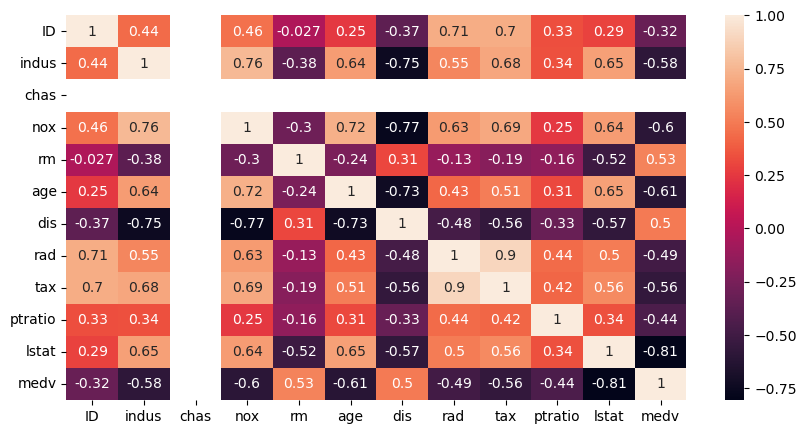

In [9]:
plt.figure(figsize=(10,5))
sns.heatmap(df.corr(numeric_only=True),annot=True)
plt.show()

In [10]:
x=df.drop(columns='medv')
x.head()

,ID,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat
0,1,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98
1,2,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14
2,4,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94
3,7,7.87,0,0.524,6.012,66.6,5.5605,5,311,15.2,12.43
4,11,7.87,0,0.524,6.377,94.3,6.3467,5,311,15.2,20.45


In [11]:
y=df['medv']
y.head()

0    24.0
1    21.6
2    33.4
3    22.9
4    15.0
Name: medv, dtype: float64

## spliting the data for the traing and testing

In [12]:
X_train,X_test,y_train,y_test=train_test_split(x,y,test_size=0.2)

In [13]:
X_train.shape,X_test.shape,y_train.shape,y_test.shape

((212, 11), (53, 11), (212,), (53,))

## Decision Tree Regressor

In [14]:
tree = DecisionTreeRegressor()

In [15]:
tree.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


## Testing

In [16]:
y_pred = tree.predict(X_test)

In [17]:
y_pred

array([16.4, 12. ,  8.8, 13.1, 21.2, 21.7, 14.9, 19.1, 14.1, 18.3, 13.3,
       11.9, 23.4, 11.9, 20.6, 10.5, 11.7, 32.7, 27.9, 17.8,  8.8, 17.1,
       25. ,  9.5,  9.5, 16.5, 23.4, 16.2, 20.4, 13.8, 22.1, 17.8, 29.1,
       16.2, 22.3,  7.2, 19.1, 15.2, 13.6,  8.8, 23.4, 16.2, 24.3, 14.1,
       16.1, 22. , 22.2, 19.2, 13.5,  8.3, 15. , 19. , 18.2])

In [18]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test,y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test,y_pred)


print('Mean Absolute Error:-',mae)
print('Mean Squared Error:-',mse)
print('Root Mean Squared Error:-',rmse)
print('R2 score:-',r2)

Mean Absolute Error:- 2.852830188679245
Mean Squared Error:- 15.004528301886795
Root Mean Squared Error:- 3.873567903353031
R2 score:- 0.38681417675022745


## creating DataFrame for understanding 

In [19]:
evaluation = pd.DataFrame({
    "Metric":["MAE","MSE","RMSE","R2 Score"],
    "Value":[mae,mse,rmse,r2]
})

evaluation

,Metric,Value
0,MAE,2.852830
1,MSE,15.004528
2,RMSE,3.873568
3,R2 Score,0.386814


## comparision between y_test & y_pred 

In [20]:
comparison = pd.DataFrame({
    "Actual":y_test,
    "Predicted":y_pred
})

comparison.head(20)

,Actual,Predicted
232,17.7,16.4
199,17.2,12.0
208,11.0,8.8
105,17.4,13.1
50,20.8,21.2
149,20.3,21.7
230,20.0,14.9
103,23.8,19.1
195,12.5,14.1
258,21.8,18.3


### cheaking errors

In [21]:
comparison['Error'] = comparison['Actual']-comparison['Predicted']

In [22]:
comparison.head(20)

,Actual,Predicted,Error
232,17.7,16.4,1.3
199,17.2,12.0,5.2
208,11.0,8.8,2.2
105,17.4,13.1,4.3
50,20.8,21.2,-0.4
149,20.3,21.7,-1.4
230,20.0,14.9,5.1
103,23.8,19.1,4.7
195,12.5,14.1,-1.6
258,21.8,18.3,3.5


In [23]:
comparison['Error'].max()

9.1

In [24]:
comparison['Error'].min()

-13.399999999999999

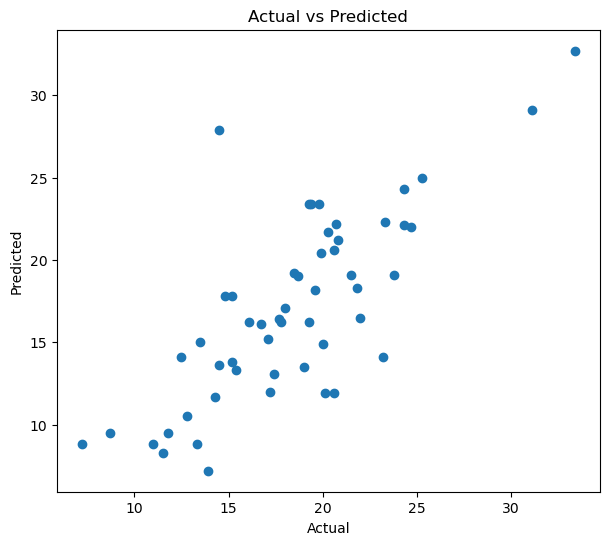

In [25]:
plt.figure(figsize=(7,6))

plt.scatter(y_test,y_pred)
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted")
plt.show()

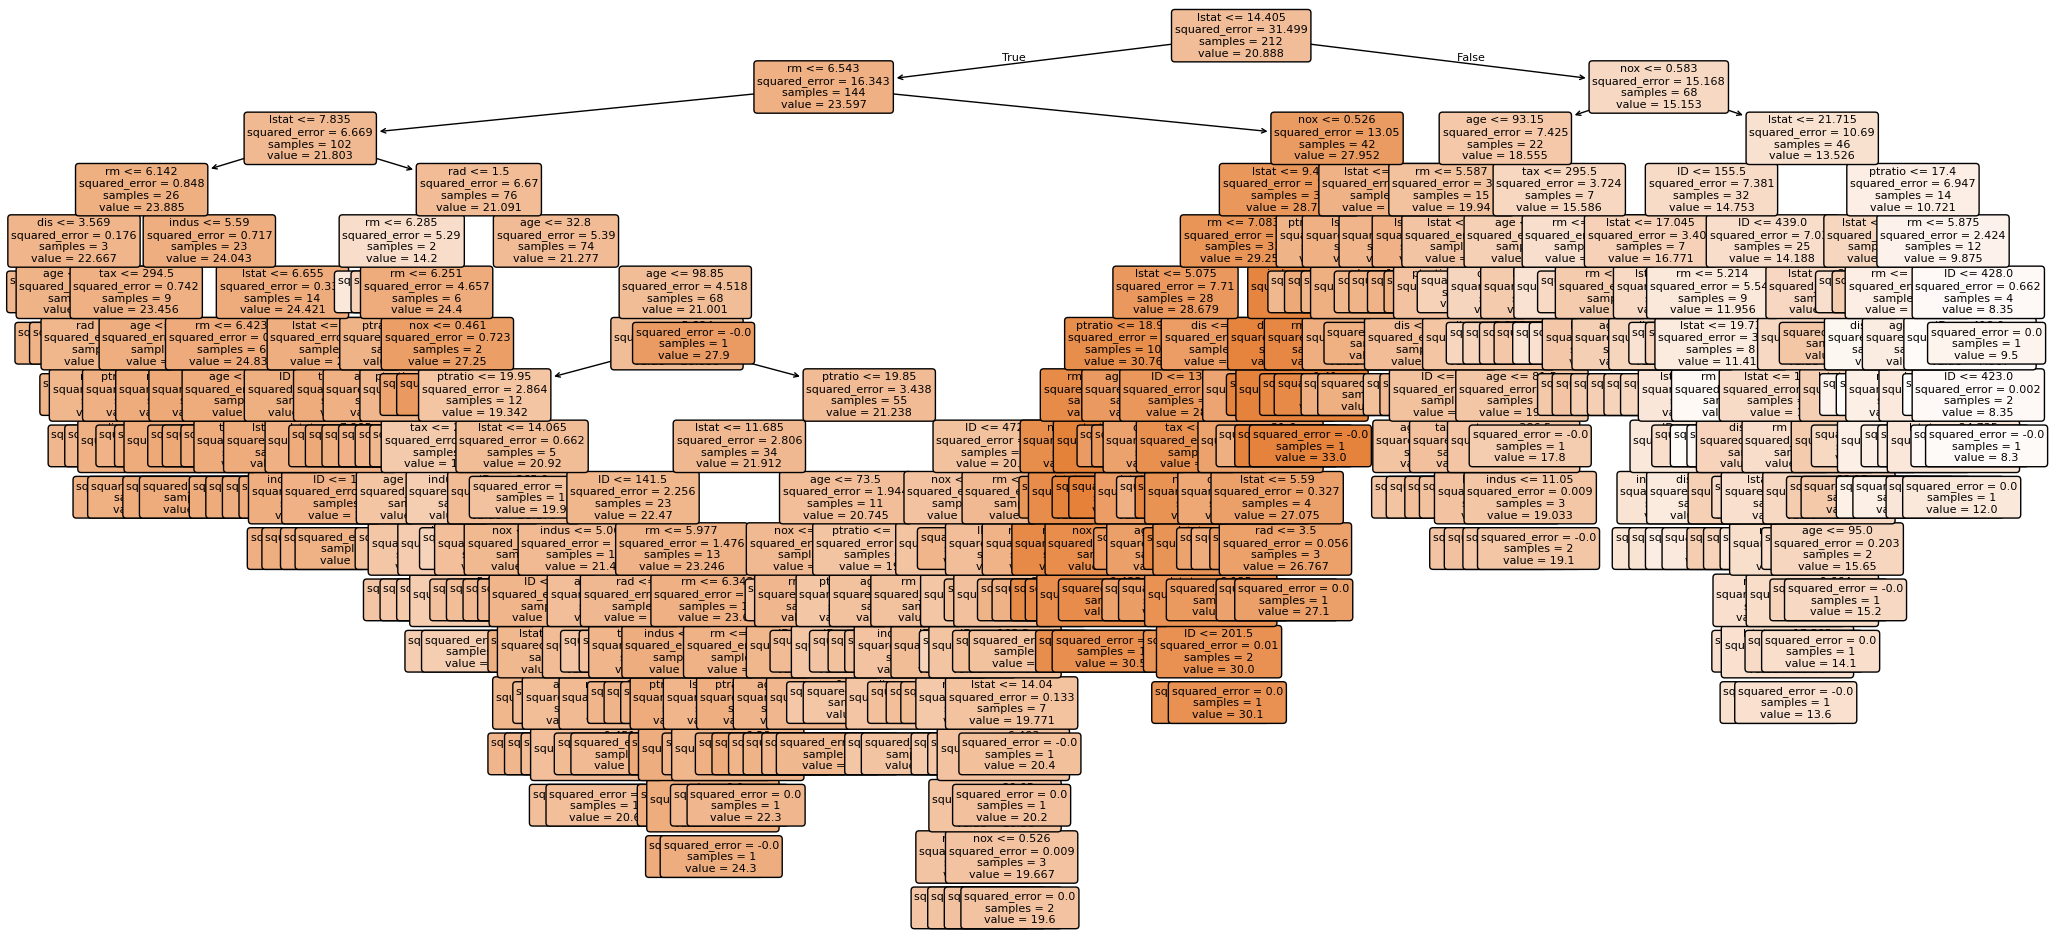

In [26]:
plt.figure(figsize=(25,12))
plot_tree(tree,feature_names=x.columns,filled=True,rounded=True,fontsize=8)
plt.show()

In [27]:
tree.feature_importances_

array([0.0287038 , 0.0026758 , 0.        , 0.08308782, 0.20617293,
       0.04158173, 0.00929001, 0.01530901, 0.00515049, 0.02298494,
       0.58504347])

## Hyperparameter Tuning

In [28]:
params = {
    "criterion":[
        "squared_error",
        "absolute_error"
    ],
    "max_depth":[
        3,5,7,10,None
    ],
    "min_samples_split":[
        2,5,10,20
    ],
    "min_samples_leaf":[
        1,2,4,6
    ],
    "max_features":[
        None,
        "sqrt",
        "log2"
    ]
}

In [29]:
grid = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_grid=params,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

In [30]:
grid.fit(X_train,y_train)

,estimator,DecisionTreeR...ndom_state=42)
,param_grid,"{'criterion': ['squared_error', 'absolute_error'], 'max_depth': [3, 5, ...], 'max_features': [None, 'sqrt', ...], 'min_samples_leaf': [1, 2, ...], ...}"
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'squared_error'


In [31]:
grid.best_params_

{'criterion': 'squared_error',
 'max_depth': 10,
 'max_features': None,
 'min_samples_leaf': 1,
 'min_samples_split': 20}

In [32]:
best_tree = grid.best_estimator_

In [33]:
pred = best_tree.predict(X_test)

In [34]:
print("MAE :",mean_absolute_error(y_test,pred))

print('MSE:',mean_squared_error(y_test,pred))

print("RMSE :",np.sqrt(mean_squared_error(y_test,pred)))

print("R2 :",r2_score(y_test,pred))

MAE : 2.721362693909864
MSE: 14.91081089444345
RMSE : 3.861451915334885
R2 : 0.39064409958950486


## Training

In [35]:
y_pred_train = tree.predict(X_train)


In [36]:
r2_train = r2_score(y_pred_train,y_train)    # r2 sccore here 100%  
r2_train

1.0

In [37]:
print("MAE :",mean_absolute_error(y_test,pred))

print("RMSE :",np.sqrt(mean_squared_error(y_test,pred)))

print("R2 :",r2_score(y_test,pred))

MAE : 2.721362693909864
RMSE : 3.861451915334885
R2 : 0.39064409958950486


In [38]:
tree_2 = DecisionTreeRegressor(max_depth = 5)

In [39]:
tree_2.fit(X_train,y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [40]:
y_pred_train = tree_2.predict(X_train)

r2_train_ = r2_score(y_train,y_pred_train)
r2_train_

0.894465314222104

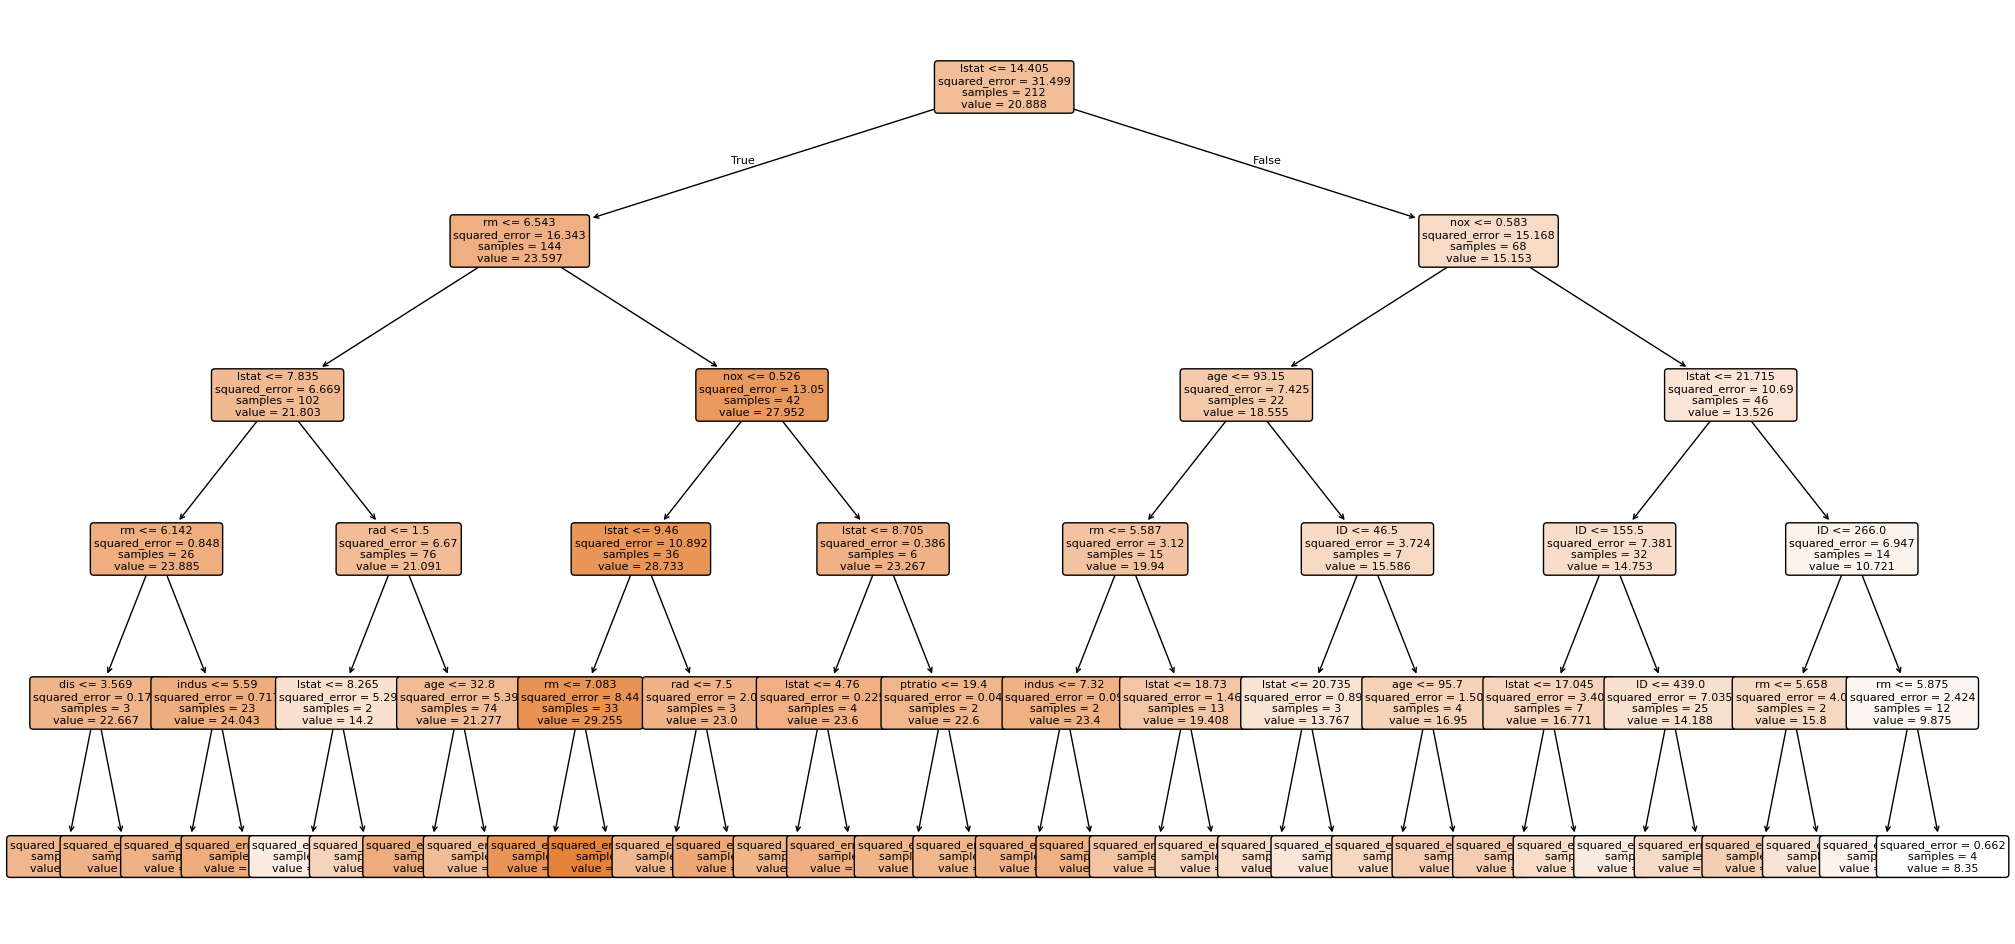

In [41]:
plt.figure(figsize=(25,12))
plot_tree(tree_2,feature_names=x.columns,filled=True,rounded=True,fontsize=8)
plt.show()

# KNN

In [42]:
KNN = KNeighborsRegressor(n_neighbors=3)

In [43]:
KNN.fit(X_train,y_train)

,n_neighbors,3
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [44]:
#checking TESTING accuracy
y_pred_test = KNN.predict(X_test)
mae_knn = mean_absolute_error(y_pred_test,y_test)
mse_knn = mean_squared_error(y_pred_test,y_test)
rmse_knn = mse_knn**0.5
r2_knn = r2_score(y_pred_test,y_test)

print("MAE",mae_knn)
print("MSE",mse_knn)
print("RMSE",rmse_knn)
print("r2 score",r2_knn)

MAE 2.6603773584905666
MSE 14.01781970649895
RMSE 3.744037887962534
r2 score 0.48271774003391854


## Hyperparameter tuning

In [45]:
params = {
    "n_neighbors": [3, 5, 7, 9, 11],
    "weights": ["uniform", "distance"],
    "algorithm": ["auto", "ball_tree", "kd_tree", "brute"],
    "leaf_size": [20, 30, 40],
    "p": [1, 2]
}

In [46]:
grid = GridSearchCV(
    estimator=KNeighborsRegressor(),
    param_grid=params,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

In [47]:
grid.fit(X_train,y_train)

,estimator,KNeighborsRegressor()
,param_grid,"{'algorithm': ['auto', 'ball_tree', ...], 'leaf_size': [20, 30, ...], 'n_neighbors': [3, 5, ...], 'p': [1, 2], ...}"
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_neighbors,11


In [48]:
grid.best_params_

{'algorithm': 'auto',
 'leaf_size': 20,
 'n_neighbors': 11,
 'p': 1,
 'weights': 'distance'}

In [49]:
best_knn = grid.best_estimator_

In [50]:
pred = best_knn.predict(X_test)

In [51]:
print("MAE :",mean_absolute_error(y_test,pred))

print('MSE:',mean_squared_error(y_test,pred))

print("RMSE :",np.sqrt(mean_squared_error(y_test,pred)))

print("R2 :",r2_score(y_test,pred))

MAE : 2.399642252009398
MSE: 9.731116637978309
RMSE : 3.119473775811925
R2 : 0.6023212028566103


In [52]:
pred = best_knn.predict(X_train)

In [53]:
print("MAE :",mean_absolute_error(y_train,pred))

print('MSE:',mean_squared_error(y_train,pred))

print("RMSE :",np.sqrt(mean_squared_error(y_train,pred)))

print("R2 :",r2_score(y_train,pred))

MAE : 0.0
MSE: 0.0
RMSE : 0.0
R2 : 1.0


## RandomForestRegressor

In [54]:
RFR = RandomForestRegressor()

In [55]:
RFR.fit(X_train,y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [56]:
#checking training accuracy
y_pred_train = RFR.predict(X_train)
mae_rfr = mean_absolute_error(y_pred_train,y_train)
mse_rfr = mean_squared_error(y_pred_train,y_train)
rmse_rfr = mse_rfr**0.5
r2_rfr = r2_score(y_pred_train,y_train)

print("MAE",mae_rfr)
print("MSE",mse_rfr)
print("RMSE",rmse_rfr)
print("r2 score",r2_rfr)

MAE 0.6893726415094338
MSE 0.9268575518867933
RMSE 0.9627344139931808
r2 score 0.9664221777450754


In [57]:
#checking training accuracy
y_pred_test = RFR.predict(X_test)
mae_rfr = mean_absolute_error(y_pred_test,y_test)
mse_rfr = mean_squared_error(y_pred_test,y_test)
rmse_rfr = mse_rfr**0.5
r2_rfr = r2_score(y_pred_test,y_test)

print("MAE",mae_rfr)
print("MSE",mse_rfr)
print("RMSE",rmse_rfr)
print("r2 score",r2_rfr)

MAE 2.0007358490566074
MSE 7.057632396226424
RMSE 2.656620484041035
r2 score 0.6919205272032816


## Hyperparameter Tuning RFR

In [ ]:
params = {
    "n_estimators": [100, 200, 300],
    "max_depth": [5, 10, 15, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2", None]
}

In [ ]:
grid = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=params,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

In [60]:
grid.fit(X_train, y_train)

,estimator,RandomForestR...ndom_state=42)
,param_grid,"{'max_depth': [5, 10, ...], 'max_features': ['sqrt', 'log2', ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,100


In [61]:
grid.best_params_

{'max_depth': None,
 'max_features': None,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'n_estimators': 100}

In [62]:
best_rfr = grid.best_estimator_

In [63]:
pred = best_rfr.predict(X_test)

In [71]:
print("MAE :",mean_absolute_error(y_test,pred))

print('MSE:',mean_squared_error(y_test,pred))

print("RMSE :",np.sqrt(mean_squared_error(y_test,pred)))

print("R2 :",r2_score(y_test,pred))

MAE : 2.108679245283022
MSE: 7.542595509433971
RMSE : 2.746378617276571
R2 : 0.6917588781307626


In [68]:
import pickle

with open("Boston_House_Price_Model.pkl", "wb") as file:
    pickle.dump(RFR, file)

In [69]:
import joblib

RFR = joblib.load("Boston_House_Price_Model.pkl")

In [70]:
df.head(26)

,ID,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
0,1,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
1,2,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
2,4,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
3,7,7.87,0,0.524,6.012,66.6,5.5605,5,311,15.2,12.43,22.9
4,11,7.87,0,0.524,6.377,94.3,6.3467,5,311,15.2,20.45,15.0
5,12,7.87,0,0.524,6.009,82.9,6.2267,5,311,15.2,13.27,18.9
6,13,7.87,0,0.524,5.889,39.0,5.4509,5,311,15.2,15.71,21.7
7,14,8.14,0,0.538,5.949,61.8,4.7075,4,307,21.0,8.26,20.4
8,15,8.14,0,0.538,6.096,84.5,4.4619,4,307,21.0,10.26,18.2
9,16,8.14,0,0.538,5.834,56.5,4.4986,4,307,21.0,8.47,19.9
